# 01 - Data Acquisition and Exploratory Data Analysis

Dataset: UCI Heart Disease (Cleveland).

The data is first examined in its raw form, to understand its contents,
identify quality problems and decide what has to be corrected. The cleaning
and preprocessing decisions are then applied, and the features and their
relationship with heart disease are studied.

The analysis is statistical. The meaning of each column is taken from the UCI
documentation, and no clinical interpretation is attempted.

1. Data acquisition
2. Data source and scope
3. Data dictionary
4. Dataset overview
5. Data quality checks
6. Missing values
7. Target variable
8. Data cleaning and preprocessing
9. Feature distributions
10. Outliers
11. Features against the target
12. Correlation
13. Subgroup check
14. Preprocessing preview
15. Summary of decisions

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# The notebook sits in notebooks/, so the project root is one level up.
ROOT = Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw"

# Lets the notebook import the project code in src/.
sys.path.insert(0, str(ROOT))

# All figures are also saved as PNG files, so they can be used in the report.
FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

## 1. Data acquisition

Objective: The raw files are made available for the analysis. The download
is carried out by `src/data/download.py`, which reads one file per
hospital from the UCI repository and saves it as a CSV file.

The original hospital records have 76 columns. A 14-column version of each
hospital's data is provided by UCI in files named `processed.*.data`. The word
"processed" in these names refers to this reduction from 76 to 14 columns,
which was done before the files were published on the UCI repository. No
processing has been done in this project at this stage, and these four files
are treated as the raw data.

Files already present in `data/raw/` are reused. In this way the notebook does
not depend on the UCI website every time it is run, and the analysis is always
done on the same copy of the data.

In [2]:
from src.config import HOSPITALS
from src.data.download import download, raw_path

for hospital in HOSPITALS:
    path = raw_path(hospital, RAW_DIR)
    if path.exists():
        status = "already present"
    else:
        download(hospital, RAW_DIR)
        status = "downloaded"
    print(f"{hospital:12s} {status:16s} {path.name}")

cleveland    already present  heart_cleveland_raw.csv
hungarian    already present  heart_hungarian_raw.csv
switzerland  already present  heart_switzerland_raw.csv
va           already present  heart_va_raw.csv


## 2. Data source and scope

Objective: The dataset contains records from four hospitals. The four
14-column hospital files are compared to identify which of them is suitable
for modelling.

The following is stated on the UCI dataset page:

> This database contains 76 attributes, but all published experiments refer to
> using a subset of 14 of them. In particular, the Cleveland database is the
> only one that has been used by ML researchers to date.

This statement is verified below using the data itself.

In [3]:
# Each hospital file is read into its own table.
# "?" was already read as missing by the download script.
raw = {}
for hospital in HOSPITALS:
    raw[hospital] = pd.read_csv(raw_path(hospital, RAW_DIR))

# One summary row is built for each hospital.
rows = []
for hospital, table in raw.items():
    rows.append({
        "hospital": hospital,
        "patients": len(table),
        # A complete row has no missing value in any of the 14 columns.
        "complete rows": len(table.dropna()),
        # A cholesterol of 0 is taken to mean "not recorded".
        "chol recorded as 0": int((table["chol"] == 0).sum()),
        # "num" above 0 means disease. The mean of True/False values is the share of True.
        "patients with disease (%)": round((table["num"] > 0).mean() * 100),
    })

summary = pd.DataFrame(rows).set_index("hospital")
summary

,patients,complete rows,chol recorded as 0,patients with disease (%)
hospital,,,,
cleveland,303,297,0,46
hungarian,294,1,0,36
switzerland,123,0,123,93
va,200,1,49,74


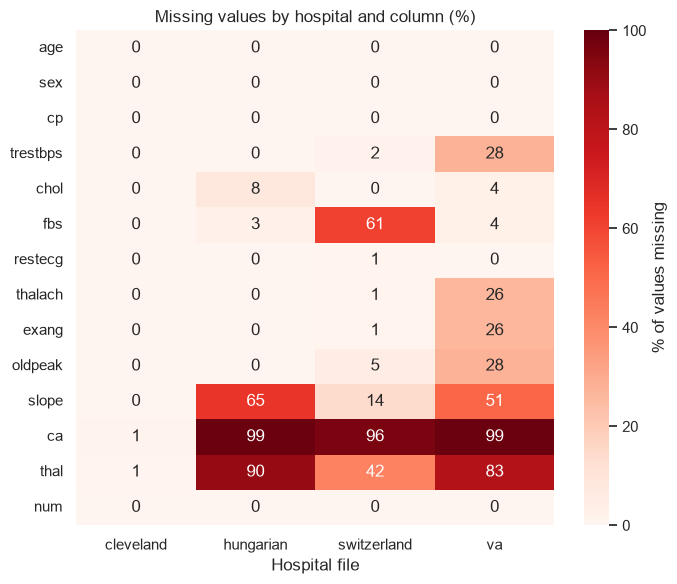

In [4]:
# Share of missing values in every column, for every hospital.
# isna() marks each empty cell as True, so the mean of a column is the share
# of empty cells in it.
missing_pct = pd.DataFrame()
for hospital, table in raw.items():
    missing_pct[hospital] = table.isna().mean() * 100

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(missing_pct, annot=True, fmt=".0f", cmap="Reds", vmin=0, vmax=100,
            cbar_kws={"label": "% of values missing"}, ax=ax)
ax.set_title("Missing values by hospital and column (%)")
ax.set_xlabel("Hospital file")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_missing_by_hospital.png", dpi=150)
plt.show()

Observations

- The Cleveland file has 297 complete rows out of 303. Only 2 complete rows
  out of 617 are found in the other three files taken together.
- `ca` is missing for 99% of the Hungarian, 96% of the Switzerland and 99% of
  the VA patients. `thal` is missing for 90%, 42% and 83%, and `slope` for
  65%, 14% and 51%.
- In the Switzerland file, cholesterol is recorded as 0 for all 123 patients,
  and in the VA file for 49 patients. A value of 0 for every patient in a
  file indicates that the value was not recorded, so these are taken as
  missing values stored as a number.
- The share of patients with disease differs widely: 46% in Cleveland, 36% in
  Hungarian, 93% in Switzerland and 74% in VA.

Inference

- The UCI statement is supported by the data. Only the Cleveland file is
  complete enough for training a model.
- If the other three files were included, `ca` would have to be filled for
  98% of their patients, `thal` for 78% and `slope` for 50%. This would
  amount to creating data that was never recorded.
- Since the disease share differs so much between hospitals, a model trained
  on the combined data could learn the hospital in place of the patient's risk.

Decision

- Only the Cleveland file (303 patients, 14 columns) is used for modelling.
- The other three files are retained in `data/raw/` only for this comparison.

## 3. Data dictionary

Objective: The meaning and the type of each column are recorded. The
meanings and the value labels are quoted from the UCI documentation
(`heart-disease.names`), with the spelling corrected and one long label
shortened. The labels of `num` are as given on the UCI dataset page. Nothing
is added to them. The types are assigned in this notebook.

The types used are the standard ones:

- Numerical - a quantity. It is continuous when it is a measurement and
  discrete when it is a count.
- Categorical - a group label. It is binary when there are two groups,
  nominal when the groups have no order, and ordinal when they have a
  natural order.

The categorical features are stored as number codes in the file. A code such
as `cp = 4` is only a label for a category and has no numeric meaning.

| Column | Meaning (UCI documentation) | Type | Values |
|---|---|---|---|
| `age` | age in years | Numerical (continuous) | recorded as whole numbers |
| `sex` | sex | Categorical (binary) | 1 = male, 0 = female |
| `cp` | chest pain type | Categorical (nominal) | 1 = typical angina, 2 = atypical angina, 3 = non-anginal pain, 4 = asymptomatic |
| `trestbps` | resting blood pressure (in mm Hg on admission to the hospital) | Numerical (continuous) | mm Hg |
| `chol` | serum cholesterol in mg/dl | Numerical (continuous) | mg/dl |
| `fbs` | fasting blood sugar > 120 mg/dl | Categorical (binary) | 1 = true, 0 = false |
| `restecg` | resting electrocardiographic results | Categorical (nominal) | 0 = normal, 1 = having ST-T wave abnormality, 2 = showing probable or definite left ventricular hypertrophy |
| `thalach` | maximum heart rate achieved | Numerical (continuous) | unit not given |
| `exang` | exercise induced angina | Categorical (binary) | 1 = yes, 0 = no |
| `oldpeak` | ST depression induced by exercise relative to rest | Numerical (continuous) | unit not given |
| `slope` | the slope of the peak exercise ST segment | Categorical (ordinal) | 1 = upsloping, 2 = flat, 3 = downsloping |
| `ca` | number of major vessels (0-3) colored by fluoroscopy | Numerical (discrete) | 0 to 3 |
| `thal` | no description is given, only the three values | Categorical (nominal) | 3 = normal, 6 = fixed defect, 7 = reversible defect |
| `num` | diagnosis of heart disease | Target (ordinal) | 0 = no presence, 1 to 4 = presence |

In total there are 6 numerical features (5 continuous and 1 discrete) and
7 categorical features (3 binary, 3 nominal and 1 ordinal), along with the
target.

`ca` is a count, so its type is numerical. As it takes only four values, it
can be handled by a model either as a number or as categories. This choice is
made later in this notebook, after its relationship with the target is seen.

## 4. Dataset overview

Objective: The size of the data, its appearance and the storage type of
each column are examined.

In [5]:
df = raw["cleveland"]
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [6]:
# One line per column: how it is stored, how many different values, how many missing.
overview = pd.DataFrame({
    "stored as": df.dtypes.astype(str),
    "different values": df.nunique(),
    "missing": df.isna().sum(),
})
overview

,stored as,different values,missing
age,float64,41,0
sex,float64,2,0
cp,float64,4,0
trestbps,float64,50,0
chol,float64,152,0
fbs,float64,2,0
restecg,float64,3,0
thalach,float64,91,0
exang,float64,2,0
oldpeak,float64,40,0


Observations

- The file has 303 rows and 14 columns, as stated in the UCI documentation.
- All 13 feature columns are stored as decimal numbers (`float64`), including
  the categorical ones. For example, `sex` appears as 1.0 and 0.0.
- The categorical features and `ca` have only 2 to 4 different values each.
  The continuous features have many different values.

Inference

- The decimal type is a result of the way the source file is written (`63.0`,
  `1.0`). It is not an error, but it hides which features are categorical.

Decision

- During cleaning, the categorical features are stored as whole numbers
  wherever the feature has no missing value, so that a code is read as a
  label (1, 0) and not as a quantity (1.0, 0.0). A feature with a missing
  value has to remain a decimal, because a whole-number column cannot hold an
  empty cell.
- During modelling, numerical and categorical features are treated
  differently. Numerical features are scaled, and categorical features are
  encoded, since a model would otherwise read the codes as quantities.

## 5. Data quality checks

Objective: The data is checked for three problems that can silently affect
a model.

1. Duplicate rows - the same patient entered twice.
2. Invalid category codes - a value that is not listed in the data dictionary.
3. Impossible values in numerical features - for example, a blood pressure of 0.

In [7]:
# 5.1 Duplicate rows
print("Duplicate rows:", int(df.duplicated().sum()))

Duplicate rows: 0


In [8]:
# 5.2 Invalid codes: the values found are compared with the values allowed
#     in the data dictionary (section 3).
VALID_CODES = {
    "sex": [0, 1],
    "cp": [1, 2, 3, 4],
    "fbs": [0, 1],
    "restecg": [0, 1, 2],
    "exang": [0, 1],
    "slope": [1, 2, 3],
    "ca": [0, 1, 2, 3],
    "thal": [3, 6, 7],
    "num": [0, 1, 2, 3, 4],
}

rows = []
for col, allowed in VALID_CODES.items():
    # The different values present in the column, as whole numbers.
    # Missing values are left out here. They are covered in section 6.
    found = sorted(df[col].dropna().astype(int).unique().tolist())

    # Rows whose value is not in the allowed list.
    invalid_rows = int((~df[col].dropna().isin(allowed)).sum())

    rows.append({
        "column": col,
        "values allowed": allowed,
        "values found": found,
        "rows with invalid value": invalid_rows,
    })
pd.DataFrame(rows).set_index("column")

,values allowed,values found,rows with invalid value
column,,,
sex,"[0, 1]","[0, 1]",0
cp,"[1, 2, 3, 4]","[1, 2, 3, 4]",0
fbs,"[0, 1]","[0, 1]",0
restecg,"[0, 1, 2]","[0, 1, 2]",0
exang,"[0, 1]","[0, 1]",0
slope,"[1, 2, 3]","[1, 2, 3]",0
ca,"[0, 1, 2, 3]","[0, 1, 2, 3]",0
thal,"[3, 6, 7]","[3, 6, 7]",0
num,"[0, 1, 2, 3, 4]","[0, 1, 2, 3, 4]",0


In [9]:
# 5.3 Impossible values in the continuous features.
# The limits below are broad limits chosen only to catch entry errors
# (like 0 or 9999). They are not clinical limits.
LIMITS = {
    "age": (18, 100),        # years
    "trestbps": (80, 220),   # mm Hg
    "chol": (100, 600),      # mg/dl
    "thalach": (60, 220),    # maximum heart rate
    "oldpeak": (0, 7),       # ST depression
}

rows = []
for col, limits in LIMITS.items():
    low = limits[0]
    high = limits[1]

    # True for each value that is below the lower limit or above the upper limit.
    too_low = df[col] < low
    too_high = df[col] > high

    rows.append({
        "column": col,
        "lowest value": df[col].min(),
        "highest value": df[col].max(),
        "allowed range": f"{low} to {high}",
        "values outside range": int(too_low.sum() + too_high.sum()),
    })
pd.DataFrame(rows).set_index("column")

,lowest value,highest value,allowed range,values outside range
column,,,,
age,29.0,77.0,18 to 100,0
trestbps,94.0,200.0,80 to 220,0
chol,126.0,564.0,100 to 600,0
thalach,71.0,202.0,60 to 220,0
oldpeak,0.0,6.2,0 to 7,0


Observations

- No duplicate rows are found.
- Every categorical feature, as well as `ca` and `num`, contains only the
  values listed in the data dictionary.
- All values of the continuous features lie within the broad limits. `age`
  ranges from 29 to 77, `trestbps` from 94 to 200, `chol` from 126 to 564,
  `thalach` from 71 to 202 and `oldpeak` from 0 to 6.2.

Inference

- No entry errors of the kinds checked here are present in the Cleveland file.
  The only remaining quality problem is the missing values, which are examined
  in the next section.
- Some values are high, such as a cholesterol of 564. These are examined as
  outliers in section 10.

Decision

- No rows are removed and no values are corrected at this stage, since no
  duplicate, invalid code or impossible value was found.
- The same checks are to be written as unit tests, so that the pipeline fails
  if invalid data is received later.

## 6. Missing values

Objective: The number of missing values, and the columns and patients
affected, are examined so that a suitable method of handling them can be
chosen.

In [10]:
missing = df.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0].to_string())
print()
print("Total missing values:", int(missing.sum()), "out of", df.size, "cells")
print("Rows with a missing value:", int(df.isna().any(axis=1).sum()), "out of", len(df))

Columns with missing values:
ca      4
thal    2

Total missing values: 6 out of 4242 cells
Rows with a missing value: 6 out of 303


In [11]:
# The affected rows are listed to see which patients they belong to.
missing_rows = df[df.isna().any(axis=1)]
missing_rows

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


In [12]:
# Rows with a missing value are compared with the complete rows.
# has_missing is True for a row that has at least one empty cell.
has_missing = df.isna().any(axis=1)

groups = {
    "complete": df[~has_missing],       # ~ means "not"
    "with missing": df[has_missing],
}

rows = []
for name, group in groups.items():
    rows.append({
        "group": name,
        "rows": len(group),
        "disease share (%)": round((group["num"] > 0).mean() * 100),
        "average age": round(group["age"].mean(), 1),
    })

compare = pd.DataFrame(rows).set_index("group")
compare

,rows,disease share (%),average age
group,,,
complete,297,46,54.5
with missing,6,33,49.3


Observations

- Only 6 values are missing out of 4,242 cells (about 0.14%). They occur in
  two columns: 4 in `ca` and 2 in `thal`.
- The 6 values belong to 6 different patients. No patient has both values
  missing.
- Of these 6 patients, 4 have no disease and 2 have disease, so both classes
  are represented.
- `thal` is a categorical feature and `ca` is a count with only four values.
  A missing value in them cannot be replaced by an average. A value such as
  `thal = 4.7` has no meaning.

Inference

- The amount of missing data is very small, so any reasonable method is
  expected to give almost the same model. The choice is therefore made on the
  correctness of the method.
- Three options are considered:

| Option | Method | Advantage | Limitation |
|---|---|---|---|
| A. Fill in the cleaning step | Each gap is replaced by the most common value of the column | Simple. The cleaned file has no gaps | The fill value is computed from all rows, including rows that later become test data (data leakage) |
| B. Drop the 6 rows | 297 complete rows are kept | No value is made up | 2% of a small dataset is lost. A rule is still needed in the API when a request has a missing value |
| C. Fill inside the model pipeline | The gaps are kept in the cleaned file. The most common value is learnt by the pipeline from the training data only | No leakage. The same rule is applied in the API | 6 empty cells remain in the cleaned file |

Decision

Option C is selected. The missing values are kept in the cleaned file and are
filled inside the model pipeline, for the following reasons.

- Fair evaluation. The fill value is calculated from the data. If it is
  calculated before the data is split into training and test rows, the test
  rows take part in the calculation, and the test score no longer represents
  unseen patients. Inside the pipeline, the fill value is calculated from the
  training rows only.
- Same handling in training and in the API. A request to the deployed API
  can also have a missing value. The pipeline is saved together with the
  model, so the same fill rule is applied to a new patient without any
  separate code.
- No loss of data. All 303 patients are retained, which matters in a
  dataset of this size.

The fill value is the most common value of the column, learnt from the
training rows. An average is not suitable, because `thal` is categorical and
`ca` takes only four whole-number values. The most common value is always a
valid value of the column.

As a consequence, 6 empty cells remain in `data/processed/heart_clean.csv`.
This is intentional and is not an omission in the cleaning.

## 7. Target variable

Objective: The spread of the diagnosis column `num` is examined, and the
form of the target for the model is decided.

It is stated on the UCI page that the value ranges from 0 (no presence) to 4,
and that experiments have concentrated on separating presence (1, 2, 3, 4)
from absence (0). A binary target is also required by the assignment.

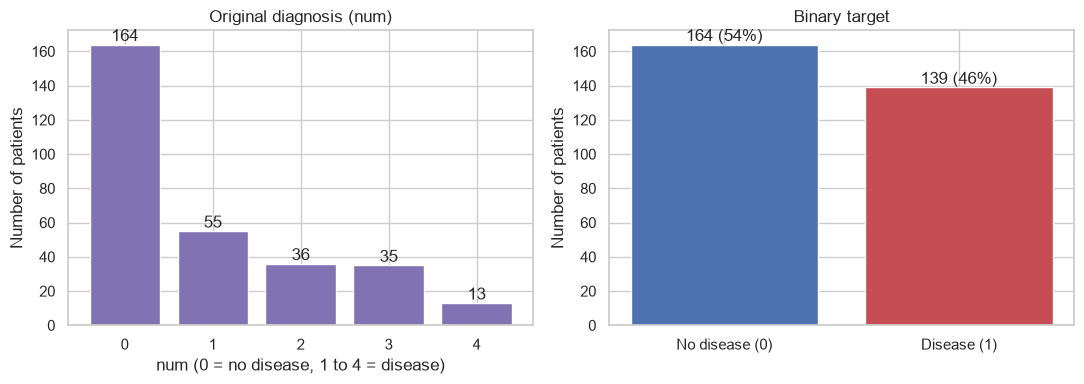

In [13]:
num_counts = df["num"].value_counts().sort_index()

# Binary version: any value above 0 means disease is present.
binary = (df["num"] > 0).astype(int)
binary_counts = binary.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bars = axes[0].bar(num_counts.index.astype(str), num_counts.values, color="#8172b3")
axes[0].bar_label(bars)
axes[0].set_title("Original diagnosis (num)")
axes[0].set_xlabel("num (0 = no disease, 1 to 4 = disease)")
axes[0].set_ylabel("Number of patients")

bars = axes[1].bar(["No disease (0)", "Disease (1)"], binary_counts.values,
                   color=["#4c72b0", "#c44e52"])

# Each bar is labelled with its count and its share, for example "164 (54%)".
bar_labels = []
for count in binary_counts.values:
    bar_labels.append(f"{count} ({count / len(df):.0%})")
axes[1].bar_label(bars, labels=bar_labels)
axes[1].set_title("Binary target")
axes[1].set_ylabel("Number of patients")

fig.tight_layout()
fig.savefig(FIG_DIR / "01_target_distribution.png", dpi=150)
plt.show()

Observations

- In the original column, 164 patients have the value 0. The disease values
  are thinly spread: 55, 36, 35 and only 13 patients for the values 1, 2, 3
  and 4.
- After conversion to a binary target, there are 164 patients without disease
  (54%) and 139 with disease (46%).

Inference

- Prediction of the five original values is not practical. With only 13
  patients in the highest group, that group cannot be learnt reliably.
- The binary target is nearly balanced. Oversampling or class weights are
  therefore not required, and accuracy can be reported along with precision,
  recall and ROC-AUC.

Decision

- A new column `target` is created: 0 when `num` is 0, and 1 when `num` is
  1 to 4.
- The `num` column is dropped afterwards, so that it cannot leak into the
  features.

## 8. Data cleaning and preprocessing

Objective: The decisions taken in sections 2 to 7 are applied to the data.

Preprocessing covers every step that makes the data ready for a model.
Cleaning is the part of it that corrects problems in the data. The steps
required for this dataset, and the place where each is carried out, are listed
below.

| Step | Carried out in | Reason |
|---|---|---|
| Only the Cleveland file is used | `src/data/download.py` | Only this file is nearly complete (section 2) |
| Storage type of categorical features corrected | `src/data/preparation.py` | A fixed correction. Nothing is learnt from the data |
| Binary `target` created and `num` dropped | `src/data/preparation.py` | A fixed rule (section 7) |
| Missing values filled | Model pipeline | The fill value is learnt from the training rows only (section 6) |
| Categorical features encoded | Model pipeline | The categories are learnt from the training rows, and the same encoding is applied in the API |
| Numerical features scaled | Model pipeline | The mean and spread are learnt from the training rows only |

The rule followed is this: a step based on a fixed rule is applied in the
cleaning script, and a step that learns something from the data is placed in
the model pipeline. In this way nothing is learnt from the test rows, and the
deployed API applies exactly the same steps as the training.

No rows are removed, since no duplicate, invalid code or impossible value was
found (section 5). The same checks are repeated as unit tests in `tests/`.

The cleaning code in `src/data/preparation.py` is run from the cell below, and
`data/processed/heart_clean.csv` is saved.

In [14]:
from src.config import CATEGORICAL, NUMERIC, TARGET
from src.data.preparation import prepare

# prepare() reads the raw CSV, cleans it, saves the cleaned CSV and returns it.
clean_df = prepare(
    raw_path=raw_path("cleveland", RAW_DIR),
    clean_path=ROOT / "data" / "processed" / "heart_clean.csv",
)

print("Shape after cleaning:", clean_df.shape)
print("Missing values left for the pipeline:", int(clean_df.isna().sum().sum()))
print()
print("Target counts:")
print(clean_df[TARGET].value_counts().sort_index().to_string())

Shape after cleaning: (303, 14)
Missing values left for the pipeline: 6

Target counts:
target
0    164
1    139


In [15]:
# The cleaned data is checked to confirm that only the intended changes were made.
features = NUMERIC + CATEGORICAL

# 1. No row was added or removed.
assert len(clean_df) == len(df)

# 2. Feature values are the same as in the raw file (only the storage type changed).
assert clean_df[features].astype(float).equals(df[features].astype(float))

# 3. The target follows the rule "num above 0 means disease".
assert (clean_df[TARGET] == (df["num"] > 0).astype(int)).all()

print("All three checks passed.")

# Storage type of each column after cleaning (shown sideways to save space).
pd.DataFrame({"stored as": clean_df.dtypes.astype(str)}).T

All three checks passed.


,age,trestbps,chol,thalach,oldpeak,sex,cp,fbs,restecg,exang,slope,ca,thal,target
stored as,float64,float64,float64,float64,float64,int64,int64,int64,int64,int64,int64,float64,float64,int64


Observations

- The cleaned file has 303 rows and 14 columns: 13 features and `target`.
- 6 missing values remain, as decided in section 6.
- The target has 164 patients without disease and 139 with disease.
- The categorical features without missing values are now stored as whole
  numbers. `ca` and `thal` remain as decimals because they still contain
  empty cells.

Inference

- Very little cleaning is required, because the Cleveland file was already in
  good condition. Most of the effort so far went into confirming this and
  not assuming it.
- All later work (the remaining sections, training, tests and the API) starts
  from `data/processed/heart_clean.csv`.

## 9. Feature distributions

Objective: The distribution of each feature is examined on its own, to
understand its range and shape, and to identify categories with very few
patients. The cleaned data is used from this section onwards.

### 9.1 Continuous features

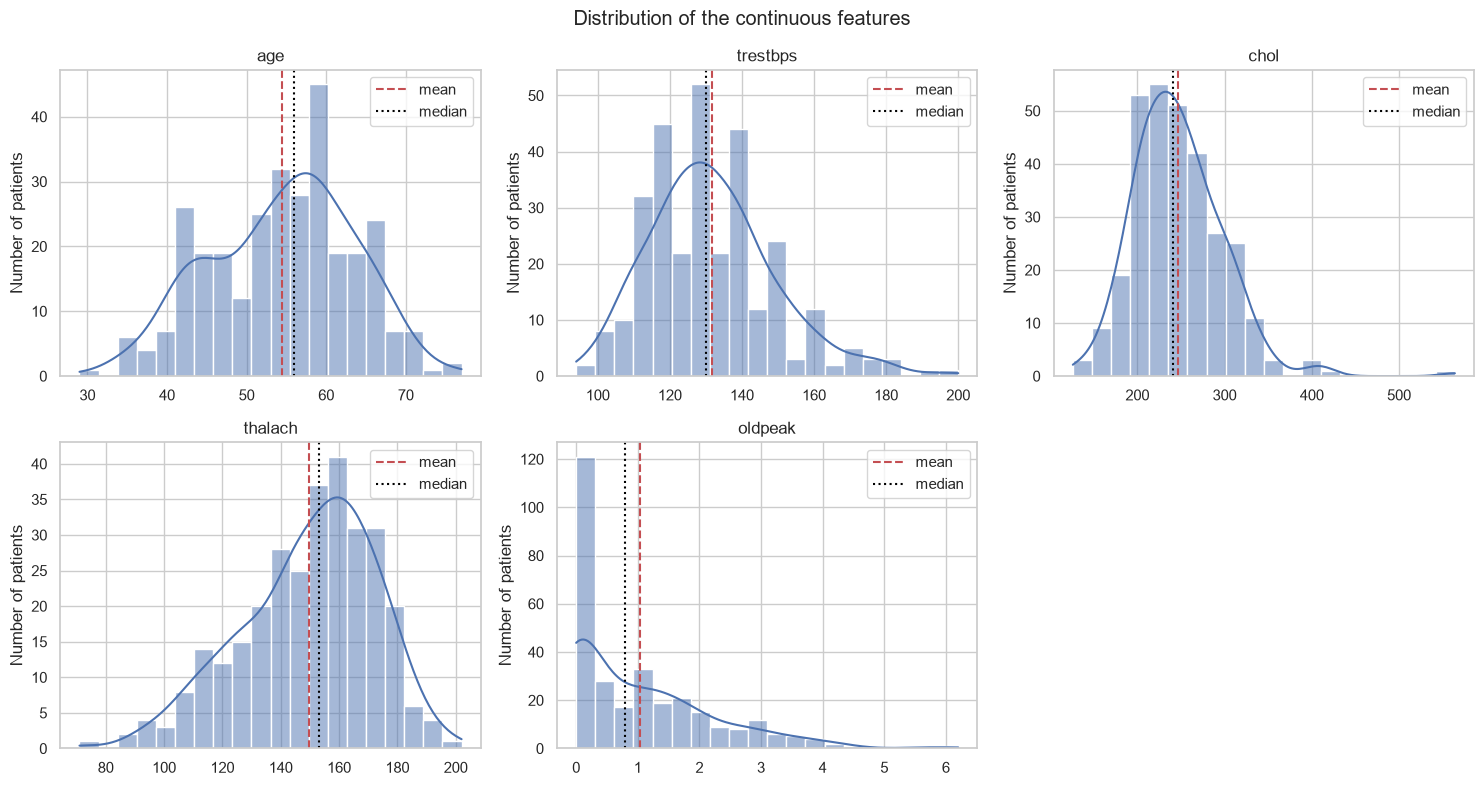

In [16]:
data = clean_df   # the cleaned data from section 8

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()   # the 2 x 3 grid of plots as a simple list

for i, col in enumerate(NUMERIC):
    ax = axes[i]
    sns.histplot(data[col], bins=20, kde=True, color="#4c72b0", ax=ax)

    # The mean and the median are marked. A gap between the two lines shows
    # that the distribution is skewed (stretched to one side).
    ax.axvline(data[col].mean(), color="#c44e52", linestyle="--", label="mean")
    ax.axvline(data[col].median(), color="black", linestyle=":", label="median")

    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Number of patients")
    ax.legend()

axes[5].axis("off")   # there are five features, so the sixth plot is left empty
fig.suptitle("Distribution of the continuous features")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_numerical_histograms.png", dpi=150)
plt.show()

In [17]:
# Summary numbers for the same features.
# Skewness is 0 for a symmetric distribution. A positive value means a long
# tail towards high values, and a negative value a long tail towards low values.
stats = data[NUMERIC].agg(["mean", "median", "std", "min", "max", "skew"]).T
stats.round(2)

,mean,median,std,min,max,skew
age,54.44,56.0,9.04,29.0,77.0,-0.21
trestbps,131.69,130.0,17.60,94.0,200.0,0.71
chol,246.69,241.0,51.78,126.0,564.0,1.14
thalach,149.61,153.0,22.88,71.0,202.0,-0.54
oldpeak,1.04,0.8,1.16,0.0,6.2,1.27


Observations

- `age` is nearly symmetric (skewness -0.21), with a mean of 54.4 and a median
  of 56 years. 206 of the 303 patients are between 50 and 69 years, and only
  15 are below 40.
- `thalach` is slightly skewed to the left (-0.54), with a mean of 149.6 and a
  median of 153.
- `trestbps` (0.71), `chol` (1.14) and `oldpeak` (1.27) are skewed to the
  right. A small number of patients have high values.
- `oldpeak` is exactly 0 for 99 patients (33%), so its distribution is not
  bell-shaped.
- The ranges are very different. `oldpeak` lies between 0 and 6.2, while
  `chol` lies between 126 and 564.

Inference

- Because the ranges differ so much, a model that is sensitive to scale, such
  as regularised Logistic Regression, would not treat the features equally.
- The skew is moderate. Tree-based models are not affected by it. A log
  transformation is also not possible for `oldpeak` as it stands, because the
  logarithm of 0 is not defined.
- Most of the patients are 50 years or older. The trained model cannot be
  relied upon for patients below 40, as only 15 of them are present in the
  data.

Decision

- The numerical features are standardised (mean 0, standard deviation 1)
  inside the model pipeline.
- No transformation is applied for the skew.
- The high values are examined as possible outliers in the next section.

### 9.2 Categorical features and `ca`

`ca` is numerical, but it takes only four values, so it is shown here with
one bar for each value.

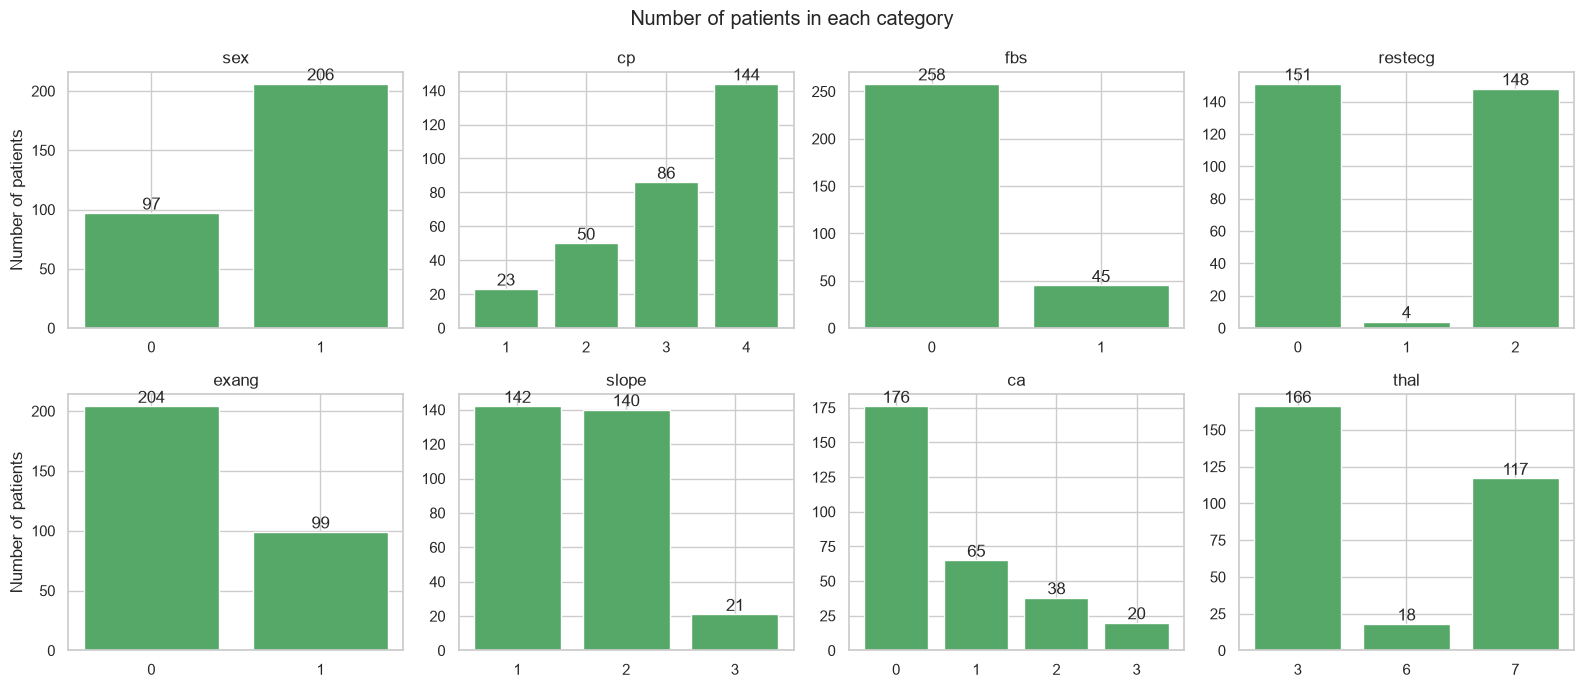

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.ravel()

for i, col in enumerate(CATEGORICAL):
    ax = axes[i]

    # Number of patients in each category. Missing values are not counted,
    # so the bars of "ca" and "thal" add up to 299 and 301.
    counts = data[col].value_counts().sort_index()

    # The codes are shown as whole numbers on the axis.
    labels = []
    for code_value in counts.index:
        labels.append(str(int(code_value)))

    bars = ax.bar(labels, counts.values, color="#55a868")
    ax.bar_label(bars)
    ax.set_title(col)

axes[0].set_ylabel("Number of patients")
axes[4].set_ylabel("Number of patients")
fig.suptitle("Number of patients in each category")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_categorical_counts.png", dpi=150)
plt.show()

In [19]:
# The smallest category of each feature, to find categories with very few patients.
rows = []
for col in CATEGORICAL:
    counts = data[col].value_counts()
    rows.append({
        "feature": col,
        "smallest category": int(counts.idxmin()),
        "patients": int(counts.min()),
        "share (%)": round(counts.min() / len(data) * 100, 1),
    })

pd.DataFrame(rows).set_index("feature").sort_values("patients")

,smallest category,patients,share (%)
feature,,,
restecg,1,4,1.3
thal,6,18,5.9
ca,3,20,6.6
slope,3,21,6.9
cp,1,23,7.6
fbs,1,45,14.9
sex,0,97,32.0
exang,1,99,32.7


Observations

- 206 patients (68%) are male and 97 (32%) are female.
- Nearly half of the patients (144, or 47.5%) have `cp = 4` (asymptomatic).
- `restecg = 1` occurs in only 4 patients (1.3%).
- Three more categories have fewer than 25 patients each: `thal = 6` (18),
  `ca = 3` (20) and `slope = 3` (21). `cp = 1` has 23.
- `fbs = 1` occurs in 45 patients (15%).

Inference

- A category with very few patients gives little information to a model. The
  effect estimated for `restecg = 1` from 4 patients cannot be trusted.
- During cross-validation, the data is divided into parts. A part used for
  training may contain no patient with `restecg = 1`, while the part used for
  testing contains one. The encoder must not fail in this case.
- The data is dominated by male patients, so the results for women rest on
  97 patients. This is examined in section 13.

Decision

- The rare categories are retained and not merged with others, since merging
  medical categories needs a clinical reason.
- The encoder in the pipeline is set to ignore a category that was not seen
  during training.

## 10. Outliers

Objective: The continuous features are checked for values that lie far
from the rest, and it is decided whether such values should be removed,
capped or retained.

The IQR rule is used. The IQR (inter-quartile range) is the range covered by
the middle 50% of the values. A value is flagged when it lies more than
1.5 times the IQR below the first quartile or above the third quartile. The
same rule is used to draw the points in a box plot.

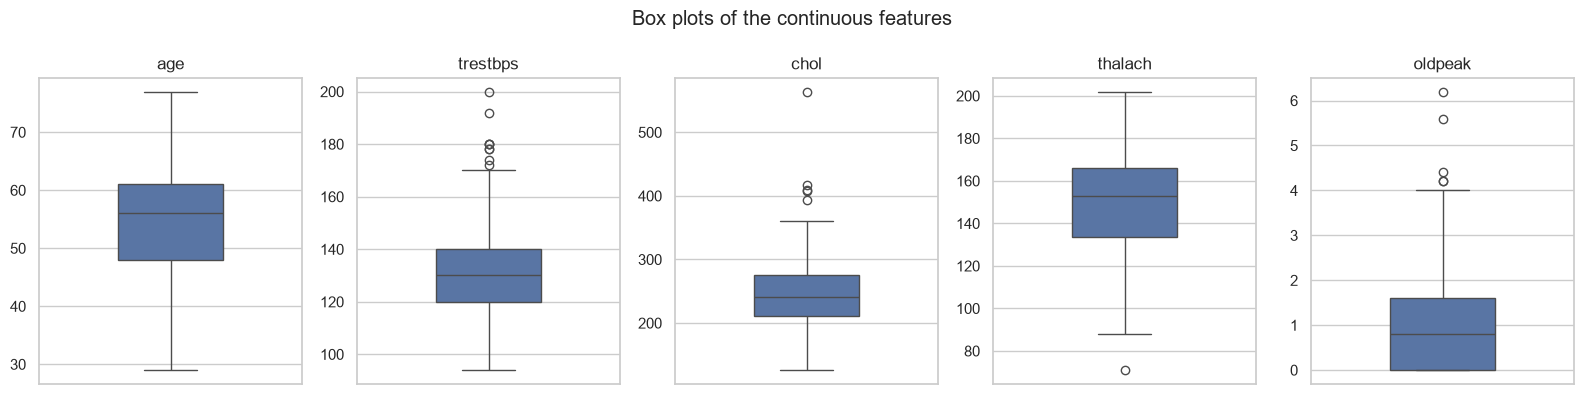

In [20]:
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for i, col in enumerate(NUMERIC):
    sns.boxplot(y=data[col], color="#4c72b0", width=0.4, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_ylabel("")

fig.suptitle("Box plots of the continuous features")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_boxplots.png", dpi=150)
plt.show()

In [21]:
rows = []

# True for a patient who has an outlier value in at least one feature.
outlier_rows = pd.Series(False, index=data.index)

for col in NUMERIC:
    q1 = data[col].quantile(0.25)   # first quartile: 25% of the values are below it
    q3 = data[col].quantile(0.75)   # third quartile: 75% of the values are below it
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    is_outlier = (data[col] < lower) | (data[col] > upper)
    outlier_rows = outlier_rows | is_outlier

    rows.append({
        "feature": col,
        "lower limit": round(lower, 1),
        "upper limit": round(upper, 1),
        "outliers": int(is_outlier.sum()),
        "outlier values": sorted(data.loc[is_outlier, col].tolist()),
    })

pd.set_option("display.max_colwidth", 80)   # so that the list of values is not cut short
pd.DataFrame(rows).set_index("feature")

,lower limit,upper limit,outliers,outlier values
feature,,,,
age,28.5,80.5,0,[]
trestbps,90.0,170.0,9,"[172.0, 174.0, 178.0, 178.0, 180.0, 180.0, 180.0, 192.0, 200.0]"
chol,115.0,371.0,5,"[394.0, 407.0, 409.0, 417.0, 564.0]"
thalach,84.8,214.8,1,[71.0]
oldpeak,-2.4,4.0,5,"[4.2, 4.2, 4.4, 5.6, 6.2]"


In [22]:
# The patients with outlier values are compared with all patients.
outlier_patients = data[outlier_rows]

print("Patients with at least one outlier value:", len(outlier_patients))
print("Of these, patients with disease:", int(outlier_patients[TARGET].sum()))
print("Disease share among them (%):", round(outlier_patients[TARGET].mean() * 100))
print("Disease share among all patients (%):", round(data[TARGET].mean() * 100))

Patients with at least one outlier value: 19
Of these, patients with disease: 13
Disease share among them (%): 68
Disease share among all patients (%): 46


Observations

- 20 values in 19 patients are flagged by the IQR rule: 9 in `trestbps`
  (172 to 200), 5 in `chol` (394 to 564), 5 in `oldpeak` (4.2 to 6.2) and 1 in
  `thalach` (71). No value of `age` is flagged.
- All flagged values are on the high side, except the one in `thalach`.
- The cholesterol value of 564 stands apart. The next highest value is 417.
- All flagged values lie within the broad limits of section 5.
- 13 of the 19 patients (68%) have heart disease, compared with 46% among all
  patients.

Inference

- The flagged values are unusual, but they lie within the broad limits of
  section 5 and show no sign of an entry error. They are therefore taken as
  genuine readings. Whether any of them is a wrong reading can be confirmed
  only by a domain expert.
- These values occur more often in patients with disease, so they carry
  information about the target. If they were removed, some of the high-risk
  patients that the model is expected to recognise would be lost.
- Standardisation uses the mean and the standard deviation, which are pulled
  slightly by an extreme value such as 564. With one such value in 303
  patients the effect is small. Tree-based models are not affected, since they
  use only the order of the values.

Decision

- No outlier is removed or capped.
- Standardisation is retained for the numerical features, as decided in
  section 9.

## 11. Features against the target

Objective: Each feature is compared between patients with and without
heart disease, to identify the features that separate the two groups.

### 11.1 Continuous features

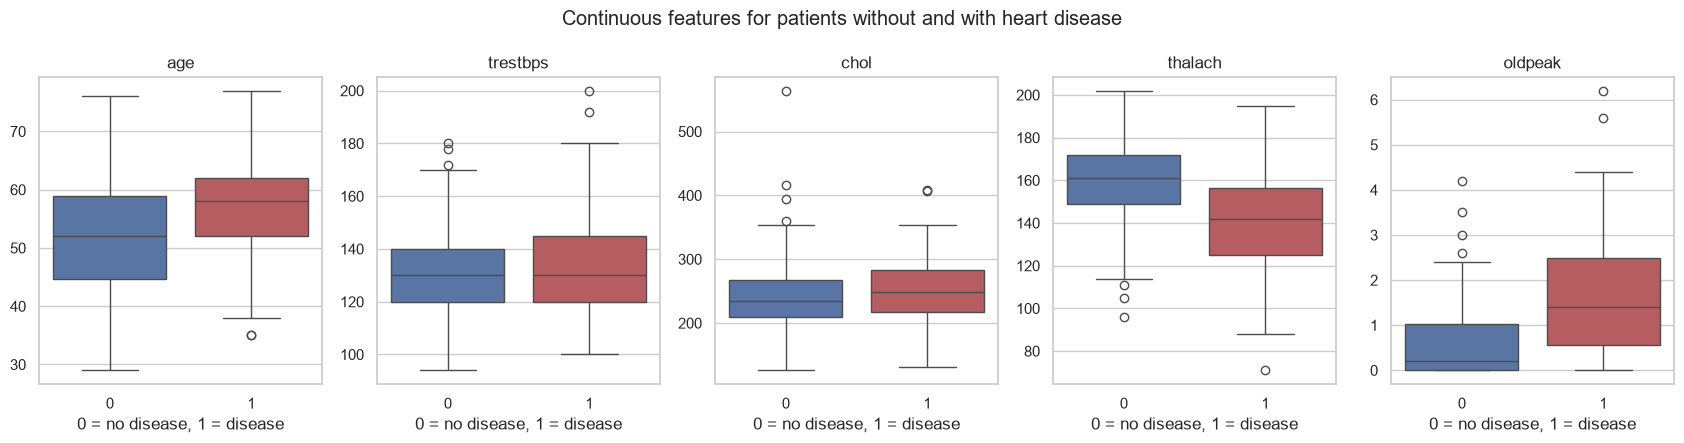

In [23]:
fig, axes = plt.subplots(1, 5, figsize=(17, 4.5))

for i, col in enumerate(NUMERIC):
    sns.boxplot(data=data, x=TARGET, y=col, hue=TARGET,
                palette=["#4c72b0", "#c44e52"], legend=False, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("0 = no disease, 1 = disease")
    axes[i].set_ylabel("")

fig.suptitle("Continuous features for patients without and with heart disease")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_numerical_by_target.png", dpi=150)
plt.show()

In [24]:
no_disease = data[data[TARGET] == 0]
disease = data[data[TARGET] == 1]

rows = []
for col in NUMERIC:
    difference = disease[col].mean() - no_disease[col].mean()
    rows.append({
        "feature": col,
        "mean (no disease)": round(no_disease[col].mean(), 1),
        "mean (disease)": round(disease[col].mean(), 1),
        "difference": round(difference, 1),
        # The features have different units, so the difference is also given
        # in units of the standard deviation. This makes the rows comparable.
        "difference in std units": round(difference / data[col].std(), 2),
    })

pd.DataFrame(rows).set_index("feature")

,mean (no disease),mean (disease),difference,difference in std units
feature,,,,
age,52.6,56.6,4.0,0.45
trestbps,129.2,134.6,5.3,0.30
chol,242.6,251.5,8.8,0.17
thalach,158.4,139.3,-19.1,-0.84
oldpeak,0.6,1.6,1.0,0.85


Observations

- The largest separation is seen in `thalach` and `oldpeak`. Patients with
  disease have a lower `thalach` (mean 139.3 against 158.4) and a higher
  `oldpeak` (1.6 against 0.6). In standard deviation units the differences
  are -0.84 and 0.85.
- Patients with disease are older by about 4 years on average (56.6 against
  52.6), a difference of 0.45 standard deviations.
- `trestbps` (134.6 against 129.2) and `chol` (251.5 against 242.6) differ
  only slightly, by 0.30 and 0.17 standard deviations. The boxes of the two
  groups overlap almost completely.

Inference

- `thalach` and `oldpeak` are the most useful continuous features. `age` is
  moderately useful. `trestbps` and `chol` are weak when taken alone.

Decision

- All five continuous features are retained. A feature that is weak on its
  own can still be useful in combination with others, so no feature is
  dropped on the basis of this section alone.

### 11.2 Categorical features and `ca`

`ca` is numerical, but it takes only four values, so it is shown here with
one bar for each value.

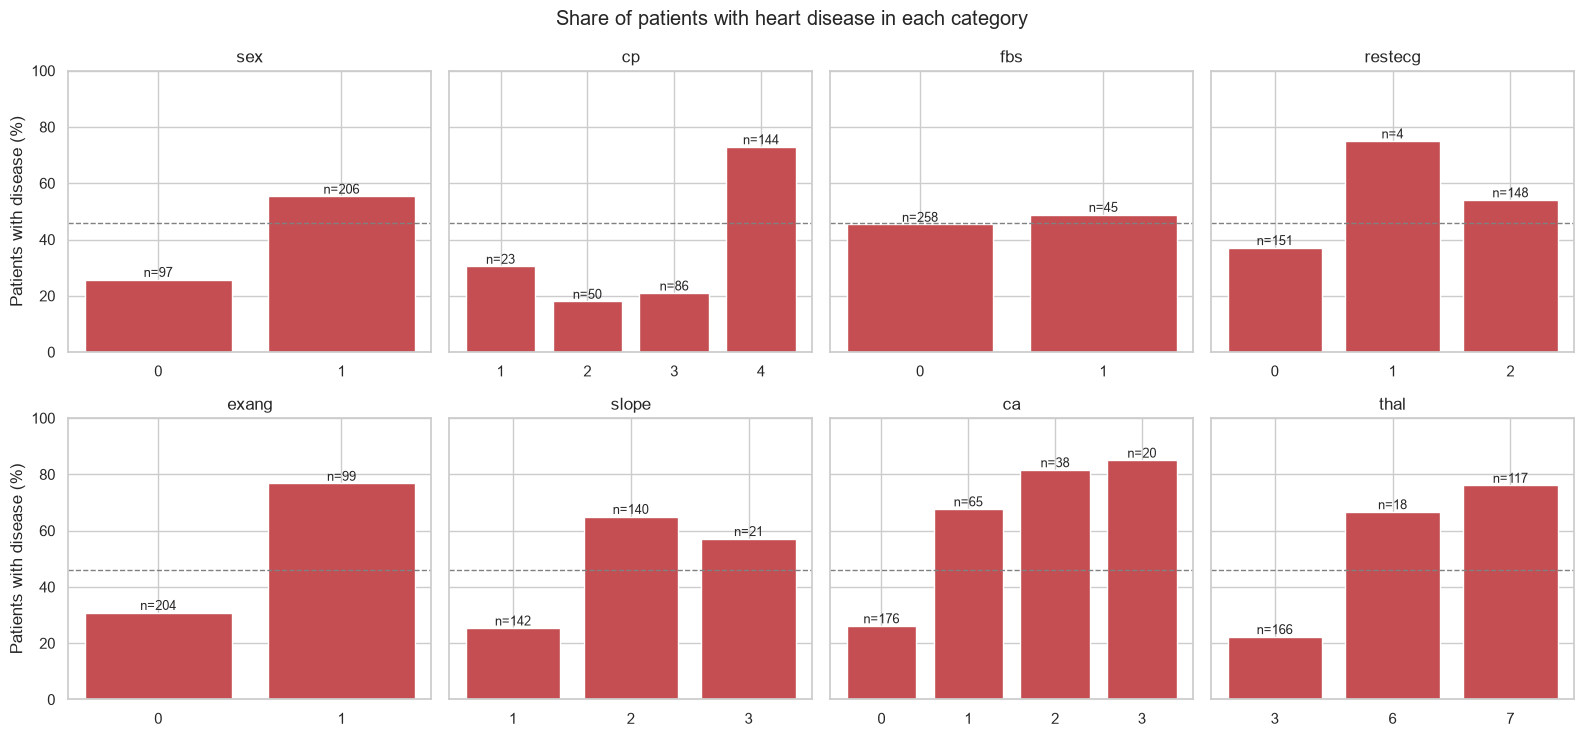

In [25]:
overall_rate = data[TARGET].mean() * 100   # disease share among all patients

fig, axes = plt.subplots(2, 4, figsize=(16, 7.5), sharey=True)
axes = axes.ravel()

for i, col in enumerate(CATEGORICAL):
    ax = axes[i]

    # For each category: the share of patients with disease, and the number of patients.
    # The mean of a 0/1 column is the share of 1s.
    rate = data.groupby(col)[TARGET].mean() * 100
    size = data.groupby(col)[TARGET].count()

    labels = []
    for code_value in rate.index:
        labels.append(str(int(code_value)))

    bars = ax.bar(labels, rate.values, color="#c44e52")

    # Each bar is labelled with the number of patients in that category,
    # because a rate from very few patients is not reliable.
    bar_labels = []
    for n in size.values:
        bar_labels.append(f"n={n}")
    ax.bar_label(bars, labels=bar_labels, fontsize=9)

    # Dashed line: disease share among all patients.
    ax.axhline(overall_rate, color="grey", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_ylim(0, 100)

axes[0].set_ylabel("Patients with disease (%)")
axes[4].set_ylabel("Patients with disease (%)")
fig.suptitle("Share of patients with heart disease in each category")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_disease_rate_by_category.png", dpi=150)
plt.show()

In [26]:
# For each feature: the categories with the lowest and the highest disease share.
rows = []
for col in CATEGORICAL:
    rate = data.groupby(col)[TARGET].mean() * 100
    rows.append({
        "feature": col,
        "lowest share (%)": round(rate.min()),
        "lowest in category": int(rate.idxmin()),
        "highest share (%)": round(rate.max()),
        "highest in category": int(rate.idxmax()),
        "gap": round(rate.max() - rate.min()),
    })

pd.DataFrame(rows).set_index("feature").sort_values("gap", ascending=False)

,lowest share (%),lowest in category,highest share (%),highest in category,gap
feature,,,,,
ca,26,0,85,3,59
cp,18,2,73,4,55
thal,22,3,76,7,54
exang,31,0,77,1,46
slope,25,1,65,2,40
restecg,37,0,75,1,38
sex,26,0,55,1,30
fbs,45,0,49,1,4


Observations

- `ca`: the disease share rises with the value of `ca`, from 26% at 0 to
  68% at 1, 82% at 2 and 85% at 3.
- `cp`: 73% of the patients with `cp = 4` (asymptomatic) have disease. For
  the values 1, 2 and 3 the share is between 18% and 30%.
- `thal`: the share is 22% for the value 3 (normal), 67% for 6 (fixed
  defect) and 76% for 7 (reversible defect).
- `exang`: 77% of the patients with `exang = 1` have disease, against 31%
  of those with `exang = 0`.
- `slope`: the share is 25% for the value 1 (upsloping), 65% for 2 (flat)
  and 57% for 3 (downsloping).
- `sex`: 55% of the men and 26% of the women have disease.
- `fbs`: the share is almost the same in both groups (45% and 49%).
- `restecg`: the share is 37% for the value 0 (normal) and 54% for the
  value 2. The 75% shown for the value 1 comes from only 4 patients.

Inference

- `ca`, `cp`, `thal` and `exang` separate the two groups strongly. `slope` and
  `sex` are moderate. `fbs` shows almost no relationship with the target.
- The disease share does not follow the order of the codes. For `cp` it does
  not rise from 1 to 4. For `slope`, which is ordinal by definition, it goes
  from 25% to 65% and then down to 57%. If these codes were given to a model
  as numbers, a linear model would assume a steady rise or fall, which is not
  what the data shows.
- For `ca` the share does rise with the count, but not in equal steps. The
  step from 0 to 1 is 42 percentage points, while the step from 2 to 3 is
  only 3. A single numerical column would force equal steps.
- The share for `restecg = 1` cannot be interpreted, as it rests on 4
  patients.

Decision

- All categorical features are one-hot encoded, including the ordinal
  feature `slope`.
- `ca` is numerical by type, but it is handled as a categorical feature in
  the model and one-hot encoded, so that each count gets its own effect.
- `fbs` is retained for now. Its contribution is checked from the feature
  importance after the models are trained.

## 12. Correlation

Objective: The relationships between the features are examined, to find
pairs of features that carry nearly the same information. Such pairs
(multicollinearity) make the coefficients of a linear model unstable.

Spearman correlation is used. It is based on the order of the values, so it
is not affected by the skew and the outliers seen earlier. The numerical
features, the binary features, the ordinal feature `slope` and the target
are included.

`cp`, `restecg` and `thal` are left out. They are nominal, so their codes are
only labels, and a correlation computed on labels has no meaning. Their
relationship with the target was shown in section 11.

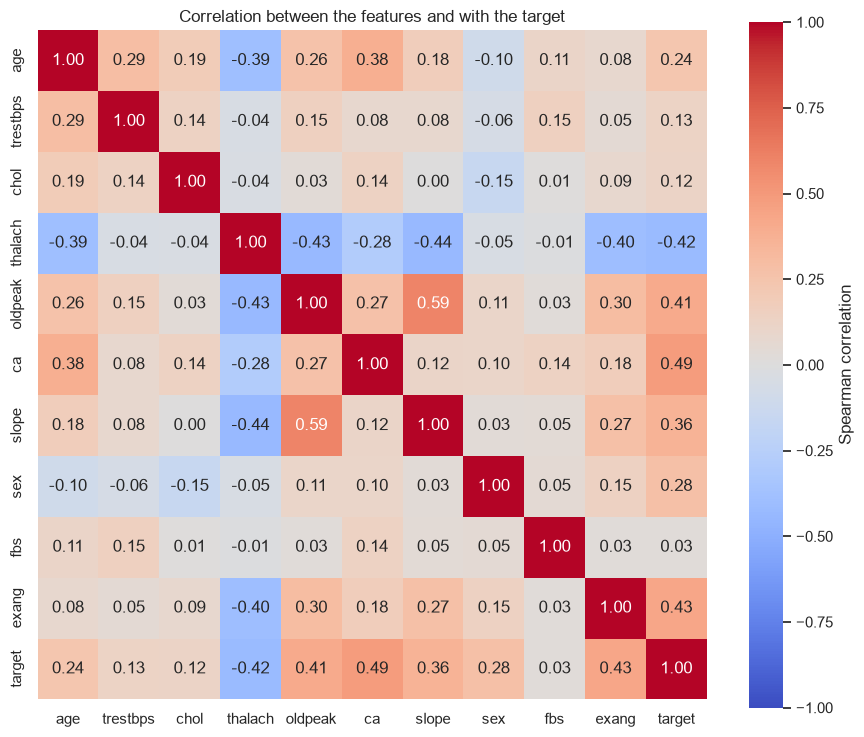

In [27]:
corr_columns = NUMERIC + ["ca", "slope", "sex", "fbs", "exang", TARGET]
corr = data[corr_columns].corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            center=0, square=True, cbar_kws={"label": "Spearman correlation"}, ax=ax)
ax.set_title("Correlation between the features and with the target")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_correlation_heatmap.png", dpi=150)
plt.show()

In [28]:
# The five strongest correlations between two features (the target is left out).
features_only = corr.drop(index=TARGET, columns=TARGET)
names = list(features_only.columns)

rows = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):      # each pair is taken once
        rows.append({
            "feature 1": names[i],
            "feature 2": names[j],
            "correlation": round(features_only.iloc[i, j], 2),
        })

pairs = pd.DataFrame(rows)
pairs["absolute value"] = pairs["correlation"].abs()
pairs.sort_values("absolute value", ascending=False).head(5).reset_index(drop=True)

,feature 1,feature 2,correlation,absolute value
0,oldpeak,slope,0.59,0.59
1,thalach,slope,-0.44,0.44
2,thalach,oldpeak,-0.43,0.43
3,thalach,exang,-0.40,0.40
4,age,thalach,-0.39,0.39


Observations

- With the target, the strongest correlations are shown by `ca` (0.49),
  `exang` (0.43), `thalach` (-0.42), `oldpeak` (0.41) and `slope` (0.36). They
  are followed by `sex` (0.28) and `age` (0.24). `trestbps` (0.13), `chol`
  (0.12) and `fbs` (0.03) are close to zero.
- Between two features, the strongest correlation is `oldpeak` with `slope`
  (0.59). The next are `thalach` with `slope` (-0.44), `thalach` with
  `oldpeak` (-0.43), `thalach` with `exang` (-0.40) and `age` with `thalach`
  (-0.39).
- No other pair of features has a correlation above 0.5 in absolute value.

Inference

- The ranking of the features against the target is consistent with
  section 11.
- Multicollinearity is usually a concern when a correlation is above about
  0.8. The highest value here is 0.59, so no two features carry the same
  information.
- For `slope`, the disease share does not rise steadily with the code
  (section 11), so its correlation with the target is read together with
  that section.

Decision

- No feature is removed or combined on the basis of correlation.

## 13. Subgroup check

Objective: The number of patients and the share with disease are examined
by sex and age band, to identify the groups for which the data is thin. A
model learns little about a group that has few patients.

In [29]:
age_band = pd.cut(data["age"], bins=[0, 44, 54, 64, 120],
                  labels=["below 45", "45 to 54", "55 to 64", "65 and above"])

rows = []
for sex_code, sex_name in [(0, "female"), (1, "male")]:
    for band in age_band.cat.categories:
        group = data[(data["sex"] == sex_code) & (age_band == band)]
        rows.append({
            "sex": sex_name,
            "age band": band,
            "patients": len(group),
            "with disease": int(group[TARGET].sum()),
            "disease share (%)": round(group[TARGET].mean() * 100),
        })

pd.DataFrame(rows).set_index(["sex", "age band"])

patients  with disease  disease share (%)
sex    age band                                               
female below 45            15             1                  7
       45 to 54            25             1                  4
       55 to 64            40            21                 52
       65 and above        17             2                 12
male   below 45            40            13                 32
       45 to 54            63            29                 46
       55 to 64            79            54                 68
       65 and above        24            18                 75

Observations

- There are 97 women and 206 men. Only 25 of the women have disease, against
  114 of the men.
- Among women below 55 years, 2 out of 40 have disease. In the band of 55 to
  64 years the share is 52% (21 out of 40).
- Among men, the share rises with age in every band: 32%, 46%, 68% and 75%.
- The smallest groups are women below 45 (15 patients) and women of 65 and
  above (17 patients).

Inference

- The model has only 25 examples of women with disease to learn from. Its
  results for women may therefore differ from its results for men, and a
  small test set cannot measure this difference precisely.

Decision

- `sex` is retained as a feature.
- During model evaluation, the results are also reported separately for men
  and women.
- The small number of women with disease is recorded as a limitation of the
  trained model.

## 14. Preprocessing preview

Objective: The preprocessing steps decided in the earlier sections are
applied once, so that their effect on the data can be seen. These are the
steps listed in section 8 as part of the model pipeline: filling of missing
values, encoding of categorical features and scaling of numerical features.

The steps are defined in `src/features/preprocessing.py`, and the same code is used
later by the training script and the API. Here they are only demonstrated.
The data is split into training rows (80%) and test rows (20%), and the steps
are fitted on the training rows alone.

In [30]:
from sklearn.model_selection import train_test_split

from src.features.preprocessing import build_preprocessor

X = data[NUMERIC + CATEGORICAL]   # the 13 features
y = data[TARGET]

# stratify=y keeps the disease share the same in both parts.
# random_state fixes the split, so that the result can be repeated.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# The fill values, the mean and spread for scaling, and the list of
# categories are all learnt here, from the training rows only.
preprocessor = build_preprocessor()
preprocessor.fit(X_train)

# The learnt steps are then applied to both parts.
columns = preprocessor.get_feature_names_out()
train_ready = pd.DataFrame(preprocessor.transform(X_train), columns=columns, index=X_train.index)
test_ready = pd.DataFrame(preprocessor.transform(X_test), columns=columns, index=X_test.index)

print("Rows:                  train", len(X_train), "| test", len(X_test))
print("Missing values before: train", int(X_train.isna().sum().sum()), "  | test", int(X_test.isna().sum().sum()))
print("Missing values after:  train", int(train_ready.isna().sum().sum()), "  | test", int(test_ready.isna().sum().sum()))
print("Columns before:", X_train.shape[1], "| after:", train_ready.shape[1])

Rows:                  train 242 | test 61
Missing values before: train 2   | test 4
Missing values after:  train 0   | test 0
Columns before: 13 | after: 28


In [31]:
# The fill values that were learnt from the training rows for "ca" and "thal".
categorical_imputer = preprocessor.named_transformers_["categorical"].named_steps["impute"]

rows = []
for col, fill_value in zip(CATEGORICAL, categorical_imputer.statistics_):
    if col in ["ca", "thal"]:
        rows.append({"feature": col, "fill value learnt from training rows": int(fill_value)})

pd.DataFrame(rows).set_index("feature")

,fill value learnt from training rows
feature,
ca,0
thal,3


In [32]:
# Mean and standard deviation of the scaled numerical features.
# In the training rows they are exactly 0 and 1. In the test rows they are
# only close to 0 and 1, because the scaling was learnt from the training rows.
scaled = pd.DataFrame({
    "train mean": train_ready[NUMERIC].mean(),
    "train std": train_ready[NUMERIC].std(),
    "test mean": test_ready[NUMERIC].mean(),
    "test std": test_ready[NUMERIC].std(),
})
scaled.round(2)

,train mean,train std,test mean,test std
age,-0.0,1.0,-0.06,1.03
trestbps,-0.0,1.0,0.21,0.99
chol,0.0,1.0,-0.30,0.86
thalach,-0.0,1.0,-0.08,1.05
oldpeak,0.0,1.0,0.18,1.16


In [33]:
# The first three training rows after preprocessing.
# A column such as "cp_4.0" is 1 when cp is 4 and 0 otherwise.
pd.set_option("display.max_columns", 40)
train_ready.head(3).round(2)

,age,trestbps,chol,thalach,oldpeak,sex_0.0,sex_1.0,cp_1.0,cp_2.0,cp_3.0,cp_4.0,fbs_0.0,fbs_1.0,restecg_0.0,restecg_1.0,restecg_2.0,exang_0.0,exang_1.0,slope_1.0,slope_2.0,slope_3.0,ca_0.0,ca_1.0,ca_2.0,ca_3.0,thal_3.0,thal_6.0,thal_7.0
180,-0.73,-0.40,0.46,0.71,-0.45,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
208,0.05,-0.05,0.23,0.22,-0.89,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
167,-0.06,0.06,0.72,0.40,-0.89,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0


Observations

- The split gives 242 training rows and 61 test rows.
- Before preprocessing, the training rows have 2 missing values and the test
  rows have 4. After preprocessing, none remain.
- The fill values learnt from the training rows are 0 for `ca` and 3 for
  `thal`. The 4 missing values in the test rows are filled with these same
  values.
- The 13 features become 28 columns: the 5 continuous features, and 23
  one-hot columns for the 8 features that are encoded.
- The scaled features have a mean of 0 and a standard deviation of 1 in the
  training rows. In the test rows the means lie between -0.30 and 0.21.

Inference

- The preprocessing steps named in the assignment are covered: missing
  values are handled, categorical features are encoded and numerical features
  are scaled.
- The test rows are transformed with values learnt from the training rows.
  This is why their means are not exactly 0. It confirms that nothing was
  learnt from the test rows.

Decision

- `build_preprocessor()` from `src/features/preprocessing.py` is used as the first
  step of every model pipeline in the next stage.

## 15. Summary of decisions

The decisions taken in this notebook are collected below. Each of them is
carried into the next stage, model development.

| # | Finding | Decision | Applied in |
|---|---|---|---|
| 1 | Only the Cleveland file is nearly complete (297 of 303 rows) | Only the Cleveland file is used | `src/data/download.py` |
| 2 | `num` has five values, and the higher ones are rare | A binary target is created | `src/data/preparation.py` |
| 3 | No duplicates, invalid codes or impossible values | No row is removed. The checks are repeated as unit tests | `tests/` |
| 4 | 6 missing values, in `ca` and `thal` | Filled inside the pipeline with the most common value | `src/features/preprocessing.py` |
| 5 | The numerical features have very different ranges. The skew is moderate | Standardised. No other transformation | `src/features/preprocessing.py` |
| 6 | 20 outlier values, more common in patients with disease | Retained | - |
| 7 | The disease share does not follow the order of the codes, and rises in unequal steps for `ca` | All categorical features and `ca` are one-hot encoded | `src/features/preprocessing.py` |
| 8 | Some categories are rare (`restecg = 1` has 4 patients) | Retained. The encoder ignores a category not seen in training | `src/features/preprocessing.py` |
| 9 | `fbs` shows almost no relationship with the target. `trestbps` and `chol` are weak | All 13 features are kept. Feature importance is checked after training | Model development |
| 10 | The highest correlation between two features is 0.59 (`oldpeak` with `slope`), below the level of about 0.8 that indicates repeated information | No feature is removed | - |
| 11 | The classes are nearly balanced (54% and 46%) | No resampling. The split is stratified. Accuracy, precision, recall and ROC-AUC are reported | Model development |
| 12 | The dataset has only 303 patients | Cross-validation is used to compare models | Model development |
| 13 | 68% of the patients are men. Only 25 women have disease | Results are also reported by sex. Recorded as a limitation | Model evaluation and report |

The features most strongly related to heart disease in this data are `thal`,
`cp`, `ca`, `exang`, `thalach` and `oldpeak`.